# 1B. 신고율 회귀모형

**맞히려는 값은 하루 신고 건수**다. 다만 건수를 이용량으로 직접 설명하면 "많이 타면 많이 신고된다"만 배우게 되므로(1차 분석의 문제),
이용량을 **노출(offset)**로 내리고 나머지 변수가 **신고율을 몇 배로 만드는지**를 추정한다.

> log(기대 신고 건수) = log(노출) + 요일·쉬는 날·계절·한파·비 … 의 효과

**이 노트북이 답하려는 질문**
1. 1차 분석의 모형(OLS)에서 지금 모형(음이항 + 노출)까지, 한 단계씩 바꾸면 무엇이 달라지는가? (모형 사다리)
2. 노출은 대여건수·이용시간·이동거리 중 무엇이 맞는가?
3. 한파 변수는 어떤 형태가 나은가?
4. EDA에서 뺄 가능성이 높게 나온 변수(더위·얼었다 녹은 날·평균기온·징검다리·눈)는 넣으면 나아지는가?
5. 학습을 2021-04-08부터 할 때와 2022-03부터 할 때 결과가 같은가?
6. 부품마다 효과가 어떻게 다른가?

**자료**: 2021-04-08 ~ 2024-12-31에서 운영 중단일(`no_service`)과 신고 누락 기간(`report_anomaly`, 2023-09-07 ~ 10-10)을 뺀 날.
2025년 이후(테스트 구간)는 쓰지 않는다.

**모형을 비교하는 두 가지 잣대**
- **AIC**: 같은 자료에 맞춘 모형끼리 "얼마나 잘 설명하는가"를 비교하는 값. 작을수록 좋다. 변수를 늘리면 벌점이 붙어서, 쓸모없는 변수를 넣으면 오히려 커진다. 차이가 2 미만이면 사실상 같고, 10 이상이면 뚜렷한 차이로 본다.
- **검증 오차**: 2023년까지의 자료로만 모형을 맞추고, 본 적 없는 2024년의 하루 신고 건수를 맞혀 본 평균 오차율(MAPE). 실제로 쓸 때의 성능에 가깝다.

공용 함수: `py/nbreg.py` · 결과: `output/tables/reg_*.csv`, `output/figures/reg_*.png` · 해석과 결정: `docs/notes/03_모델설계_메모.md`

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("../py")
import warnings; warnings.filterwarnings("ignore")          # statsmodels의 수렴 안내 등 반복 경고를 숨긴다
import numpy as np, pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "AppleGothic"; plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
ROOT = Path("..")
from nbreg import fit_nb, irr_table, predict_count

m = pd.read_parquet(ROOT / "data/processed/daily_master_v2.parquet")
m["no_time"] = m.date.between("2021-02-01", "2021-12-31")     # 신고에 시각이 없던 기간(같은 날 같은 자전거의 신고가 1건으로 묶인다)
m["snow_any"] = m.snow_cm >= 1                                # 눈 온 날(새로 쌓인 눈 1cm 이상)
for c in ["is_holiday", "after_off", "bridge", "cold_wave", "hot", "freeze_thaw", "snow_any", "no_time"]:
    m[c] = m[c].astype(int)                                   # True/False → 1/0 (식에 넣기 쉽게)

START, END = "2021-04-08", "2024-12-31"
keep = ~m.no_service & ~m.report_anomaly                      # 운영 중단일, 신고 누락 기간은 뺀다
d = m[m.date.between(START, END) & keep].copy()

def save_tab(x, name):
    """표를 output/tables/reg_<name>.csv로 저장하고 그대로 돌려준다"""
    x.to_csv(ROOT / f"output/tables/reg_{name}.csv"); return x

print(len(d), "일 (", d.date.min().date(), "~", d.date.max().date(), ")  연도별:", d.groupby("year").size().to_dict())

1329 일 ( 2021-04-08 ~ 2024-12-31 )  연도별: {2021: 268, 2022: 364, 2023: 331, 2024: 366}


## 1. 모형 사다리 — 1차 분석의 모형에서 한 단계씩

한 번에 최종 모형으로 가지 않고 계단을 하나씩 올라가며, 각 단계에서 무엇이 달라지는지 본다.

| 단계 | 모형 | 바꾼 것 |
|---|---|---|
| M0 | 선형회귀(OLS), 대여건수를 설명변수로 | 1차 분석의 방식. 비교 기준 |
| M1 | 포아송, 노출 없음 | 건수 자료에 맞는 모형으로(음수 예측이 안 나온다) |
| M2 | 포아송 + 노출 | 대여건수를 설명변수에서 빼고 노출로 내린다 |
| M3 | 음이항 + 노출 | 평균보다 크게 흩어지는 것(과산포)을 받아 준다 |
| M4 | M3 + 확정 변수 | 요일·쉬는 날·계절·한파·비·연도 수준 |

날씨 변수는 M0 ~ M3에서 1차 분석과 비슷한 묶음(기온, 강수, 눈, 습도, 일사)을 그대로 써서, 모형의 틀만 바뀔 때 계수가 어떻게 달라지는지 본다.
(1차 분석의 원자료 파일은 이 프로젝트에 없어서 '그대로 재현'은 하지 못하고, 새 자료에 같은 형태의 식을 적용한다.)

In [2]:
WX1 = "tavg + np.log1p(rain_mm) + snow_any + humidity + solar"       # 1차 분석과 비슷한 날씨 묶음

m0 = smf.ols(f"total_faults ~ rentals + {WX1}", data=d).fit()
print("M0 선형회귀: R² =", round(m0.rsquared, 3), "| 대여 1만 건당 신고 +", round(m0.params["rentals"] * 1e4, 1), "건 (t =", round(m0.tvalues["rentals"], 1), ")")
print("   날씨를 다 빼고 대여건수만 넣어도 R² =", round(smf.ols("total_faults ~ rentals", data=d).fit().rsquared, 3))

m1 = smf.glm(f"total_faults ~ {WX1}", data=d, family=sm.families.Poisson()).fit()
m2 = smf.glm(f"total_faults ~ {WX1}", data=d, family=sm.families.Poisson(), offset=np.log(d.rentals)).fit()
overdisp = m2.pearson_chi2 / m2.df_resid          # 1이면 포아송 가정(분산 = 평균)이 맞는 것. 훨씬 크면 과산포
print("M2 포아송+노출: 과산포 비율 =", round(overdisp, 1), "(1에 가까워야 포아송이 맞다)")
m3, a3, aic3 = fit_nb(f"total_faults ~ {WX1}", d, "rentals")
print("M3 음이항+노출: alpha =", round(a3, 4))

M0 선형회귀: R² = 0.812 | 대여 1만 건당 신고 + 34.7 건 (t = 41.0 )
   날씨를 다 빼고 대여건수만 넣어도 R² = 0.808
M2 포아송+노출: 과산포 비율 = 20.9 (1에 가까워야 포아송이 맞다)
M3 음이항+노출: alpha = 0.0532


In [3]:
# 확정 변수(체크포인트 B). 한파는 우선 cold_wave로 두고 3절에서 두 형태를 비교한다
BASE = "C(dow) + is_holiday + after_off + fs1 + fc1 + fs2 + fc2 + np.log1p(rain_mm) + np.log1p(rain_lag1)"
LEVEL = "C(year)"            # 연도별 수준 차이(레짐·정비·자전거 구성 등 해마다 달라지는 것을 한꺼번에 흡수). 설명용
m4, a4, aic4 = fit_nb(f"total_faults ~ {BASE} + cold_wave + {LEVEL}", d, "rentals")

def nb_aic_like(res_pois):   # 포아송 모형의 AIC(음이항과 같은 자료라 비교할 수 있다)
    return -2 * res_pois.llf + 2 * len(res_pois.params)

ladder = pd.DataFrame([
    {"모형": "M0 선형회귀(대여건수를 설명변수로)", "AIC": m0.aic, "기온 계수": m0.params["tavg"], "당일 비 계수": m0.params["np.log1p(rain_mm)"], "비고": f"R²={m0.rsquared:.3f}. 계수 단위는 건수"},
    {"모형": "M1 포아송, 노출 없음", "AIC": nb_aic_like(m1), "기온 계수": m1.params["tavg"], "당일 비 계수": m1.params["np.log1p(rain_mm)"], "비고": "계수 단위는 로그(이하 같음)"},
    {"모형": "M2 포아송 + 노출", "AIC": nb_aic_like(m2), "기온 계수": m2.params["tavg"], "당일 비 계수": m2.params["np.log1p(rain_mm)"], "비고": f"과산포 비율 {overdisp:.1f}"},
    {"모형": "M3 음이항 + 노출", "AIC": aic3, "기온 계수": m3.params["tavg"], "당일 비 계수": m3.params["np.log1p(rain_mm)"], "비고": f"alpha={a3:.4f}"},
    {"모형": "M4 음이항 + 노출 + 확정 변수", "AIC": aic4, "기온 계수": np.nan, "당일 비 계수": m4.params["np.log1p(rain_mm)"], "비고": f"alpha={a4:.4f}. 기온은 한파 변수로 대체"},
]).set_index("모형")
save_tab(ladder.round(4), "ladder")

,AIC,기온 계수,당일 비 계수,비고
모형,,,,
M0 선형회귀(대여건수를 설명변수로),15689.1177,1.3916,-12.4252,R²=0.812. 계수 단위는 건수
"M1 포아송, 노출 없음",74507.8226,0.0281,-0.1973,계수 단위는 로그(이하 같음)
M2 포아송 + 노출,35157.0371,0.0024,-0.0269,과산포 비율 20.9
M3 음이항 + 노출,15649.2156,0.0002,-0.0319,alpha=0.0532
M4 음이항 + 노출 + 확정 변수,14221.2292,NaN,-0.0433,alpha=0.0149. 기온은 한파 변수로 대체


읽는 법
- **M0 → M1**: 노출 없이 날씨만 넣으면, 날씨 계수가 "날씨가 좋으면 많이 타서 신고도 많다"를 대신 떠안는다(기온 계수가 크게 양수).
- **M1 → M2**: 대여건수를 노출로 내리면 그 몫이 빠지고, 날씨 계수는 "신고율"에 대한 효과만 남는다. AIC가 크게 줄어든다.
- **M2 → M3**: 과산포 비율이 1보다 훨씬 크면 포아송은 불확실성을 실제보다 작게 본다. 음이항으로 바꾸면 AIC가 다시 크게 줄어든다.
- **M3 → M4**: 요일·계절·연도 수준을 넣으면 설명력이 더 오른다.

## 2. 노출 선택 — 대여건수, 이용시간, 이동거리

두 가지를 본다.

**(1) 비례성**: offset은 "노출이 2배면 신고도 2배"라는 가정이다. 이를 확인하려고 log(노출)을 offset이 아니라 설명변수로 넣어 계수를 추정한다. **계수가 1이면** 비례 가정이 맞는 것이다. 1보다 작으면 "노출이 늘어도 신고는 그만큼 늘지 않는다"는 뜻이다.

**(2) 어느 노출이 잘 맞는가**: 같은 날들에 대해 세 노출을 각각 offset으로 넣고 AIC와 검증 오차를 비교한다.
이동거리는 기록이 깨진 날(`dist_ok`가 아닌 날)이 있어, 공정하게 비교하려고 **세 노출이 모두 있는 날만** 쓴다.

In [4]:
EXPOS = {"rentals": "대여건수", "use_hours": "이용시간", "dist_km": "이동거리"}
dc = d.dropna(subset=["dist_km"])                              # 세 노출이 모두 있는 날
print("세 노출이 모두 있는 날:", len(dc), "일 (전체", len(d), "일 중). 연도별:", dc.groupby("year").size().to_dict())

rows = []
for e, name in EXPOS.items():
    f = f"total_faults ~ {BASE} + cold_wave + {LEVEL}"
    # (1) 비례성: 노출을 offset 대신 설명변수로. offset을 거의 0(= log 1)으로 주려고 값이 1인 열을 쓴다
    r1, _, _ = fit_nb(f + f" + np.log({e})", dc.assign(one=1.0), "one")
    lo, hi = r1.conf_int().loc[f"np.log({e})"]
    # (2) offset으로 넣었을 때의 AIC
    _, _, aic = fit_nb(f, dc, e)
    rows.append({"노출": name, "log(노출) 계수": r1.params[f"np.log({e})"], "95% 하한": lo, "95% 상한": hi, "offset일 때 AIC": aic})
expo_tab = pd.DataFrame(rows).set_index("노출")
expo_tab["AIC 차이(가장 좋은 것 대비)"] = expo_tab["offset일 때 AIC"] - expo_tab["offset일 때 AIC"].min()
save_tab(expo_tab.round(3), "exposure")

세 노출이 모두 있는 날: 1083 일 (전체 1329 일 중). 연도별: {2021: 116, 2022: 270, 2023: 331, 2024: 366}


,log(노출) 계수,95% 하한,95% 상한,offset일 때 AIC,AIC 차이(가장 좋은 것 대비)
노출,,,,,
대여건수,1.097,1.056,1.139,11646.812,0.000
이용시간,0.900,0.853,0.948,11840.835,194.023
이동거리,0.873,0.826,0.919,11844.366,197.554


### 검증 오차를 재는 방법 (이후 절에서도 같이 쓴다)

2023년까지로 모형을 맞추고 2024년 하루 신고 건수를 맞혀 본다. 이때 두 가지를 조심한다.

- **연도 수준(`C(year)`)은 쓸 수 없다.** 2024년의 수준은 미리 알 수 없기 때문이다. 대신 **최근 4주 신고율**(`lvl`)을 넣는다: 어제까지 28일 동안의 신고 합계 ÷ 노출 합계의 로그. "요즘 수준"을 모형에 알려 주는 변수이고, 어제까지의 값만 쓰므로 미래 정보가 아니다.
- **그날의 노출은 안다고 본다.** 여기서는 설명변수의 쓸모를 비교하는 것이 목적이라 노출 예측 오차를 섞지 않는다(노출 예측은 1C에서 한다).

신고 누락 기간과 운영 중단일은 최근 4주 신고율 계산에서도 뺀다(그 기간의 낮은 신고율이 '요즘 수준'으로 잘못 들어가지 않게).

In [5]:
def add_level(df_all, y, expo, start=START):
    """최근 4주 신고율의 로그(lvl)를 붙인다. 어제까지 28일(정상인 날만)의 y 합계 ÷ 노출 합계.
    start 이전(다른 레짐)과 신고 누락·운영 중단일은 계산에서 뺀다. 정상인 날이 14일 미만이면 빈칸"""
    ok = (df_all.date >= start) & ~df_all.no_service & ~df_all.report_anomaly & df_all[expo].notna()
    ys, xs = df_all[y].where(ok), df_all[expo].where(ok)
    num = ys.shift(1).rolling(28, min_periods=14).sum()
    den = xs.shift(1).rolling(28, min_periods=14).sum()
    return np.log(num / den)

def valid_score(rhs, y="total_faults", expo="rentals", start=START, data=None):
    """rhs(설명변수 식)에 최근 4주 신고율을 더해, start ~ 2023-12-31로 맞추고 2024년을 맞혀 본다.
    돌려주는 것: 2024년 하루 건수의 평균 오차율(MAPE, %), 주 단위로 합친 건수의 평균 오차율(%)"""
    src = (m if data is None else data).copy()
    src["lvl"] = add_level(src, y, expo, start)
    use = src[src.date.between(start, END) & ~src.no_service & ~src.report_anomaly].dropna(subset=["lvl", expo])
    tr, va = use[use.date < "2024-01-01"], use[use.date >= "2024-01-01"]
    res, _, _ = fit_nb(f"{y} ~ {rhs} + lvl", tr, expo)
    pred = predict_count(res, va, expo)
    daily = float((np.abs(va[y] - pred) / va[y].clip(lower=1)).mean() * 100)
    wk = pd.DataFrame({"y": va[y].to_numpy(), "p": pred.to_numpy()}, index=va.date).resample("W").sum()
    return daily, float((np.abs(wk.y - wk.p) / wk.y).mean() * 100)

rows = []
common = m[m.dist_km.notna()]                                   # 공정 비교: 세 노출이 모두 있는 날만(이동거리 기록이 정상인 날)
for e, name in EXPOS.items():
    dly, wkly = valid_score(f"{BASE} + cold_wave", expo=e, data=common)
    rows.append({"노출": name, "2024 일별 오차율(%)": dly, "2024 주별 오차율(%)": wkly})
save_tab(pd.DataFrame(rows).set_index("노출").round(2), "exposure_valid")

,2024 일별 오차율(%),2024 주별 오차율(%)
노출,,
대여건수,11.21,7.23
이용시간,14.79,10.99
이동거리,13.65,9.82


## 3. 한파 변수 — 더미와 연속값

- `cold_wave`: 평균기온 −4℃ 이하면 1
- `winter_anom`: 겨울(12 ~ 2월)에 평년보다 몇 ℃ 높은가(추우면 음수), 겨울이 아니면 0

네 가지를 비교한다: 한파 변수 없음 / 더미만 / 연속값만 / 둘 다.

In [6]:
EXPO = "rentals"       # 노출은 대여건수로 확정(체크포인트 C, 2026-10-05): 2절에서 AIC·검증 오차 모두 가장 좋았다
rows = []
for name, cold in {"한파 변수 없음": "", "cold_wave(더미)": " + cold_wave", "winter_anom(연속)": " + winter_anom", "둘 다": " + cold_wave + winter_anom"}.items():
    res, _, aic = fit_nb(f"total_faults ~ {BASE}{cold} + {LEVEL}", d, EXPO)
    dly, wkly = valid_score(f"{BASE}{cold}")
    row = {"모형": name, "AIC": aic, "2024 일별 오차율(%)": dly, "2024 주별 오차율(%)": wkly}
    if "cold_wave" in cold: row["cold_wave IRR"] = np.exp(res.params["cold_wave"])
    if "winter_anom" in cold: row["winter_anom IRR(1℃당)"] = np.exp(res.params["winter_anom"])
    rows.append(row)
cold_tab = pd.DataFrame(rows).set_index("모형")
cold_tab.insert(1, "AIC 차이", cold_tab.AIC - cold_tab.AIC.min())
save_tab(cold_tab.round(3), "cold")

,AIC,AIC 차이,2024 일별 오차율(%),2024 주별 오차율(%),cold_wave IRR,winter_anom IRR(1℃당)
모형,,,,,,
한파 변수 없음,14794.963,667.564,12.661,9.353,NaN,NaN
cold_wave(더미),14221.229,93.830,10.630,6.595,1.687,NaN
winter_anom(연속),14290.705,163.306,10.583,6.794,NaN,0.954
둘 다,14127.399,0.000,10.255,6.542,1.415,0.975


## 4. EDA에서 뺄 가능성이 높게 나온 변수 — 넣으면 나아지는가

한파는 3절 결과에 따라 **두 형태를 모두** 넣는다(체크포인트 C). 그 위에 더위(`hot`), 얼었다 녹은 날(`freeze_thaw`), 평균기온(`tavg`), 징검다리 근무일(`bridge`), 눈(`snow_any`)을 모두 넣은 모형과, 하나씩 뺀 모형·모두 뺀 모형을 비교한다.

- "뺐을 때 AIC 변화"가 **양수**면 그 변수가 도움이 됐다는 뜻(빼니까 나빠짐), **음수**면 없는 편이 낫다는 뜻이다.
- 검증 오차도 같은 방향으로 읽는다(빼서 오차가 커지면 도움이 되던 변수).
- IRR의 95% 구간이 1을 포함하면 "효과가 있다고 말하기 어렵다".

In [7]:
COLD = " + cold_wave + winter_anom"        # 한파는 두 형태를 모두 넣는다(체크포인트 C)
TENT = {"hot": "더위(최고 30℃ 이상)", "freeze_thaw": "얼었다 녹은 날", "tavg": "평균기온(1℃당)", "bridge": "징검다리 근무일", "snow_any": "눈 온 날"}
full_rhs = f"{BASE}{COLD} + " + " + ".join(TENT)
full, _, aic_full = fit_nb(f"total_faults ~ {full_rhs} + {LEVEL}", d, EXPO)
v_full = valid_score(full_rhs)
it = irr_table(full)

rows = []
for v, name in TENT.items():
    rhs = f"{BASE}{COLD} + " + " + ".join(k for k in TENT if k != v)
    _, _, aic = fit_nb(f"total_faults ~ {rhs} + {LEVEL}", d, EXPO)
    vd = valid_score(rhs)
    rows.append({"변수": name, "IRR(모두 넣은 모형)": it.loc[v, "irr"], "95% 하한": it.loc[v, "lo"], "95% 상한": it.loc[v, "hi"], "p": it.loc[v, "p"],
                 "뺐을 때 AIC 변화": aic - aic_full, "뺐을 때 일별 오차 변화(%p)": vd[0] - v_full[0], "뺐을 때 주별 오차 변화(%p)": vd[1] - v_full[1]})
_, _, aic_none = fit_nb(f"total_faults ~ {BASE}{COLD} + {LEVEL}", d, EXPO)
v_none = valid_score(f"{BASE}{COLD}")
rows.append({"변수": "다섯 개 모두", "뺐을 때 AIC 변화": aic_none - aic_full, "뺐을 때 일별 오차 변화(%p)": v_none[0] - v_full[0], "뺐을 때 주별 오차 변화(%p)": v_none[1] - v_full[1]})
print("모두 넣은 모형: AIC", round(aic_full, 1), "| 2024 일별 오차율", round(v_full[0], 2), "% | 주별", round(v_full[1], 2), "%")
print("모두 뺀 모형  : AIC", round(aic_none, 1), "| 2024 일별 오차율", round(v_none[0], 2), "% | 주별", round(v_none[1], 2), "%")
save_tab(pd.DataFrame(rows).set_index("변수").round(3), "tentative")

모두 넣은 모형: AIC 14109.8 | 2024 일별 오차율 10.12 % | 주별 6.54 %
모두 뺀 모형  : AIC 14127.4 | 2024 일별 오차율 10.25 % | 주별 6.54 %


,IRR(모두 넣은 모형),95% 하한,95% 상한,p,뺐을 때 AIC 변화,뺐을 때 일별 오차 변화(%p),뺐을 때 주별 오차 변화(%p)
변수,,,,,,,
더위(최고 30℃ 이상),0.968,0.937,1.000,0.047,3.361,-0.019,-0.040
얼었다 녹은 날,1.001,0.950,1.055,0.966,-1.995,-0.004,-0.060
평균기온(1℃당),0.996,0.992,1.000,0.070,3.136,0.075,0.055
징검다리 근무일,0.939,0.866,1.017,0.122,0.107,-0.030,0.007
눈 온 날,0.908,0.811,1.016,0.092,6.949,0.113,0.024
다섯 개 모두,NaN,NaN,NaN,NaN,17.635,0.131,0.001


### 더위와 얼었다 녹은 날 — 부품별로 보면 다른가

전체 신고에서는 효과가 안 보였지만, 특정 부품에서만 효과가 있을 수 있다(예: 더위와 타이어).
평균기온·눈·징검다리는 남기기로 했으므로(체크포인트 C), **그 모형에 더위 또는 얼었다 녹은 날을 하나 더 넣었을 때** 부품별로 나아지는지 본다.

- "넣었을 때 AIC 변화"가 **음수**면 넣는 편이 낫다(−2보다 작아야 의미가 있고, −10보다 작으면 뚜렷하다). 양수면 넣어서 나빠진 것이다.
- "넣었을 때 오차 변화"가 음수면 2024년을 더 잘 맞힌 것이다.

In [8]:
KEEP = " + tavg + snow_any + bridge"                      # 남기기로 한 변수(체크포인트 C)
FINAL = f"{BASE}{COLD}{KEEP}"                             # 최종 설명변수 묶음(연도 수준·최근 수준은 따로 붙인다)
PART6 = {"total_faults": "전체", "fail_tire": "타이어", "fail_chain": "체인", "fail_saddle": "안장", "fail_pedal": "페달"}
rows = []
for col, pname in PART6.items():
    _, _, aic0 = fit_nb(f"{col} ~ {FINAL} + {LEVEL}", d, EXPO)
    v0 = valid_score(FINAL, y=col)
    for v in ("hot", "freeze_thaw"):
        r, _, aic1 = fit_nb(f"{col} ~ {FINAL} + {v} + {LEVEL}", d, EXPO)
        v1 = valid_score(f"{FINAL} + {v}", y=col)
        tt = irr_table(r).loc[v]
        rows.append({"부품": pname, "변수": TENT[v], "IRR": tt.irr, "95% 하한": tt.lo, "95% 상한": tt.hi, "p": tt.p,
                     "넣었을 때 AIC 변화": aic1 - aic0, "넣었을 때 일별 오차 변화(%p)": v1[0] - v0[0], "넣었을 때 주별 오차 변화(%p)": v1[1] - v0[1]})
save_tab(pd.DataFrame(rows).set_index(["변수", "부품"]).sort_index().round(3), "hot_freeze_by_part")

IRR  95% 하한  95% 상한      p  넣었을 때 AIC 변화  넣었을 때 일별 오차 변화(%p)  넣었을 때 주별 오차 변화(%p)
변수            부품                                                                                     
더위(최고 30℃ 이상) 안장   0.932   0.883   0.985  0.012       -12.140              -0.015              -0.024
              전체   0.968   0.937   1.000  0.049        -3.356               0.025               0.040
              체인   0.980   0.938   1.024  0.368         0.918               0.019               0.041
              타이어  0.995   0.958   1.033  0.794         1.890              -0.108              -0.142
              페달   0.992   0.942   1.044  0.749         1.829               0.028               0.009
얼었다 녹은 날      안장   1.013   0.958   1.072  0.644         1.666              -0.027              -0.110
              전체   1.000   0.949   1.054  0.997         2.000               0.010               0.059
              체인   0.993   0.919   1.073  0.867         1.924               0.010               0.129
              타이어  1.072   1.015   1.131  0.012        -8.199               0.021               0.028
              페달   1.005   0.936   1.079  0.891         1.969               0.123               0.176

## 5. 설명 모형(M4)의 효과 크기와 점검

확정 변수 + 한파 두 형태 + 평균기온·눈·징검다리(체크포인트 C에서 정한 최종 묶음)로 맞춘 모형의 효과를 "신고율이 몇 배가 되는가"(IRR)로 본다. 요일은 월요일이 기준(1.00)이다.

- 비·눈처럼 `log1p`로 넣은 변수의 IRR은 "log(1 + mm)가 1 늘 때"의 값이라 바로 읽기 어렵다. 그래서 **10mm, 30mm 올 때 몇 배인지**로 바꿔 함께 적는다.
- 잔차의 자기상관도 본다: 모형이 설명하지 못한 부분이 어제·지난주와 닮았다면 아직 빠진 것이 있다는 뜻이다.

In [9]:
rhs4 = f"{FINAL} + {LEVEL}"
m4, a4, aic4 = fit_nb(f"total_faults ~ {rhs4}", d, EXPO)
t = irr_table(m4).drop(index="Intercept")
t.index = t.index.str.replace(r"C\(dow\)\[T\.(\d)\]", lambda x: "요일: " + "월화수목금토일"[int(x.group(1)) - 1] + "(월요일 대비)", regex=True) \
                 .str.replace(r"C\(year\)\[T\.(\d+)\]", lambda x: x.group(1) + "년 수준(2021년 대비)", regex=True)
save_tab(t.round(3), "m4_irr")
display(t.round(3))
b = m4.params
print("당일 비 10mm:", round(float(np.exp(b["np.log1p(rain_mm)"] * np.log1p(10))), 3), "배 / 30mm:", round(float(np.exp(b["np.log1p(rain_mm)"] * np.log1p(30))), 3), "배")
print("전날 비 10mm:", round(float(np.exp(b["np.log1p(rain_lag1)"] * np.log1p(10))), 3), "배")
# 계절 곡선의 최고·최저(사인·코사인 4개 항을 합친 것)
doy = np.arange(1, 366); s = (b["fs1"] * np.sin(2 * np.pi * doy / 365.25) + b["fc1"] * np.cos(2 * np.pi * doy / 365.25)
                               + b["fs2"] * np.sin(4 * np.pi * doy / 365.25) + b["fc2"] * np.cos(4 * np.pi * doy / 365.25))
print("평균기온 1℃당:", round(float(np.exp(b["tavg"])), 4), "배 / 겨울에 평년보다 1℃ 따뜻하면:", round(float(np.exp(b["winter_anom"])), 3), "배 / 눈 온 날:", round(float(np.exp(b["snow_any"])), 3), "배")
# 주의: 평균기온을 함께 넣었으므로 아래 '계절 효과'는 기온으로 설명되는 몫을 뺀 나머지 계절성이다
print("계절 효과(기온 몫 제외): 가장 높은 때", (pd.Timestamp("2023-01-01") + pd.Timedelta(days=int(s.argmax()))).strftime("%m월 %d일"), round(float(np.exp(s.max())), 2), "배 / 가장 낮은 때",
      (pd.Timestamp("2023-01-01") + pd.Timedelta(days=int(s.argmin()))).strftime("%m월 %d일"), round(float(np.exp(s.min())), 2), "배 (연평균 대비)")

,irr,lo,hi,p
요일: 화(월요일 대비),1.018,0.981,1.057,0.341
요일: 수(월요일 대비),1.009,0.972,1.047,0.640
요일: 목(월요일 대비),0.980,0.945,1.017,0.284
요일: 금(월요일 대비),0.950,0.913,0.989,0.012
요일: 토(월요일 대비),0.831,0.799,0.863,0.000
요일: 일(월요일 대비),0.856,0.825,0.888,0.000
2022년 수준(2021년 대비),0.851,0.819,0.885,0.000
2023년 수준(2021년 대비),0.803,0.762,0.845,0.000
2024년 수준(2021년 대비),0.727,0.696,0.759,0.000
is_holiday,0.886,0.852,0.921,0.000


당일 비 10mm: 0.904 배 / 30mm: 0.866 배
전날 비 10mm: 0.998 배
평균기온 1℃당: 0.9952 배 / 겨울에 평년보다 1℃ 따뜻하면: 0.98 배 / 눈 온 날: 0.906 배
계절 효과(기온 몫 제외): 가장 높은 때 08월 17일 1.2 배 / 가장 낮은 때 01월 18일 0.87 배 (연평균 대비)


In [10]:
from statsmodels.tsa.stattools import acf
r = acf(m4.resid_pearson, nlags=28)
print("잔차 자기상관: 1일", round(r[1], 2), "/ 7일", round(r[7], 2), "/ 14일", round(r[14], 2), "/ 28일", round(r[28], 2), " (0에 가까울수록 남은 패턴이 없다)")
# HAC가 감안하는 자기상관 길이를 바꿔도 결론이 같은가: 주요 변수의 p값
CHK = ["cold_wave", "winter_anom", "tavg", "snow_any", "bridge", "np.log1p(rain_mm)", "np.log1p(rain_lag1)", "after_off", "is_holiday"]
chk = {}
for lag in (7, 14, 28):
    rr, _, _ = fit_nb(f"total_faults ~ {rhs4}", d, EXPO, maxlags=lag)
    chk[f"HAC {lag}일"] = rr.pvalues[CHK]
plain = smf.glm(f"total_faults ~ {rhs4}", data=d, family=sm.families.NegativeBinomial(alpha=a4), offset=np.log(d[EXPO])).fit()
chk["자기상관 무시"] = plain.pvalues[CHK]
save_tab(pd.DataFrame(chk).round(4), "hac_sensitivity")

잔차 자기상관: 1일 0.53 / 7일 0.12 / 14일 0.17 / 28일 0.08  (0에 가까울수록 남은 패턴이 없다)


,HAC 7일,HAC 14일,HAC 28일,자기상관 무시
cold_wave,0.0000,0.0000,0.0000,0.0000
winter_anom,0.0001,0.0001,0.0002,0.0000
tavg,0.0062,0.0096,0.0165,0.0008
snow_any,0.0943,0.0891,0.0853,0.0022
bridge,0.1450,0.1498,0.1406,0.1651
np.log1p(rain_mm),0.0000,0.0000,0.0000,0.0000
np.log1p(rain_lag1),0.7929,0.7878,0.7843,0.7844
after_off,0.0002,0.0002,0.0001,0.0011
is_holiday,0.0000,0.0000,0.0000,0.0000


## 6. 부품별 모형

같은 변수로 부품별 모형을 따로 맞춘다. 부품별 종속변수는 행 수(`fail_*`), 전체는 신고 건수(`total_faults`)다.

**부품별로만 넣는 변수 두 개**(체크포인트 C, 2026-10-05): 4절에서 그 부품에서만 AIC를 뚜렷이 낮춘 것.
- 안장 모형에 **더위**(`hot`, 최고 30℃ 이상): 더운 날 안장 신고가 약 7% 적다(AIC −12.1)
- 타이어 모형에 **얼었다 녹은 날**(`freeze_thaw`): 타이어 신고가 약 7% 많다(AIC −8.2)

**주의해서 읽을 것**: 두 효과는 크기가 작고(±7%), 부품 5개 × 변수 2개 = 10번 비교해서 2번 나온 것이라 우연일 가능성이 있다. 2024년 검증 오차도 넣으나 빼나 ±0.02%p로 달라지지 않았다. "효과가 있을 수 있다" 수준으로만 쓴다. 예측 모형(1C)에서는 넣은 것과 뺀 것을 다시 비교한다.
계절 효과는 사인·코사인 계수 4개로는 읽기 어려워서, **연평균 대비 가장 높은 때와 낮은 때의 배수**와 곡선 그림으로 보여 준다.
평균기온을 함께 넣었으므로 여기의 계절 곡선은 "기온으로 설명되는 몫을 뺀 나머지 계절성"이다. 부품의 실제 연중 변화는 계절 곡선과 기온 효과를 합쳐야 하므로, 그림에는 **기온 효과까지 합친 연중 곡선**(평년 기온 기준)을 그린다.

In [11]:
PARTS = {"fail_tire": "타이어", "fail_chain": "체인", "fail_saddle": "안장", "fail_pedal": "페달", "fail_terminal": "단말기", "total_faults": "전체"}
PART_EXTRA = {"fail_saddle": " + hot", "fail_tire": " + freeze_thaw"}      # 그 부품 모형에만 더 넣는 변수
def part_rhs(col):
    """부품별 설명변수 식: 공통 묶음 + (있으면) 그 부품에만 넣는 변수 + 연도 수준"""
    return f"{FINAL}{PART_EXTRA.get(col, '')} + {LEVEL}"
fits = {name: fit_nb(f"{col} ~ {part_rhs(col)}", d, EXPO) for col, name in PARTS.items()}

NORMAL = m[m.year == 2023].set_index("doy").tavg_normal.reindex(np.arange(1, 366)).to_numpy()   # 날짜별 평년 기온

def season_curve(res):
    """평년 기온인 해의 연중 신고율 곡선(연평균 = 1): 계절 사인·코사인 + 평균기온 효과를 합친 것. 한파·비·요일은 뺀 값"""
    b = res.params; doy = np.arange(1, 366)
    lin = (b["fs1"] * np.sin(2 * np.pi * doy / 365.25) + b["fc1"] * np.cos(2 * np.pi * doy / 365.25)
           + b["fs2"] * np.sin(4 * np.pi * doy / 365.25) + b["fc2"] * np.cos(4 * np.pi * doy / 365.25) + b["tavg"] * NORMAL)
    return np.exp(lin - lin.mean())

rows = {}
for name, (res, alpha, aic) in fits.items():
    b, ci = res.params, res.conf_int(); s = season_curve(res)
    f = lambda k: f"{np.exp(b[k]):.2f} ({np.exp(ci.loc[k, 0]):.2f}~{np.exp(ci.loc[k, 1]):.2f})"
    rows[name] = {"토요일(월 대비)": f("C(dow)[T.6]"), "공휴일": f("is_holiday"), "쉬는 날 다음 첫 근무일": f("after_off"),
                  "한파 더미(-4℃ 이하)": f("cold_wave"), "겨울에 평년보다 1℃ 따뜻할 때": f("winter_anom"),
                  "평균기온 1℃당": f("tavg"), "눈 온 날": f("snow_any"), "징검다리 근무일": f("bridge"),
                  "더위(안장 모형에만)": f("hot") if "hot" in b.index else "-",
                  "얼었다 녹은 날(타이어 모형에만)": f("freeze_thaw") if "freeze_thaw" in b.index else "-",
                  "당일 비 10mm": f"{np.exp(b['np.log1p(rain_mm)'] * np.log1p(10)):.2f}", "전날 비 10mm": f"{np.exp(b['np.log1p(rain_lag1)'] * np.log1p(10)):.2f}",
                  "전날 비 p값": round(float(res.pvalues["np.log1p(rain_lag1)"]), 3),
                  "연중 최고(연평균 대비)": f"{s.max():.2f} ({(pd.Timestamp('2023-01-01') + pd.Timedelta(days=int(s.argmax()))).strftime('%m월')})",
                  "연중 최저": f"{s.min():.2f} ({(pd.Timestamp('2023-01-01') + pd.Timedelta(days=int(s.argmin()))).strftime('%m월')})",
                  "2024년 수준(2021 대비)": f("C(year)[T.2024]"), "alpha": round(alpha, 4)}
save_tab(pd.DataFrame(rows), "irr_by_part")

,타이어,체인,안장,페달,단말기,전체
토요일(월 대비),0.83 (0.79~0.87),0.84 (0.80~0.88),0.76 (0.71~0.80),0.77 (0.73~0.81),0.90 (0.82~0.98),0.83 (0.80~0.86)
공휴일,0.92 (0.88~0.96),0.88 (0.83~0.92),0.80 (0.75~0.86),0.82 (0.78~0.86),0.95 (0.89~1.01),0.89 (0.85~0.92)
쉬는 날 다음 첫 근무일,1.07 (1.03~1.12),1.06 (1.01~1.11),1.08 (1.03~1.13),1.05 (1.00~1.10),0.99 (0.93~1.05),1.07 (1.03~1.11)
한파 더미(-4℃ 이하),1.33 (1.19~1.49),1.62 (1.40~1.88),1.09 (0.97~1.21),1.53 (1.32~1.78),1.09 (0.94~1.25),1.41 (1.27~1.58)
겨울에 평년보다 1℃ 따뜻할 때,0.99 (0.97~1.00),0.97 (0.96~0.98),1.02 (1.00~1.03),0.99 (0.97~1.00),0.99 (0.97~1.00),0.98 (0.97~0.99)
평균기온 1℃당,1.00 (1.00~1.01),1.00 (0.99~1.00),0.99 (0.99~1.00),1.00 (1.00~1.01),0.99 (0.99~1.00),1.00 (0.99~1.00)
눈 온 날,1.01 (0.92~1.11),0.84 (0.73~0.97),0.98 (0.86~1.12),0.83 (0.69~0.99),1.05 (0.83~1.33),0.91 (0.81~1.02)
징검다리 근무일,0.96 (0.88~1.05),0.92 (0.85~1.01),0.88 (0.81~0.96),1.00 (0.91~1.11),1.04 (0.90~1.20),0.94 (0.87~1.02)
더위(안장 모형에만),-,-,0.93 (0.88~0.98),-,-,-
얼었다 녹은 날(타이어 모형에만),1.07 (1.02~1.13),-,-,-,-,-


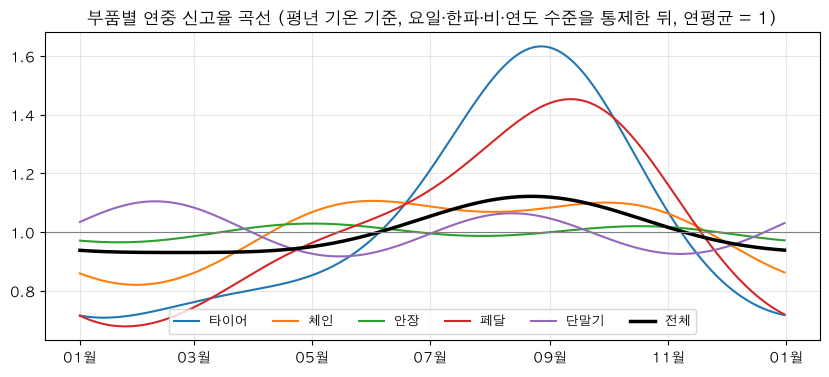

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
days = pd.date_range("2023-01-01", periods=365)
for name, (res, _, _) in fits.items():
    ax.plot(days, season_curve(res), label=name, lw=2.5 if name == "전체" else 1.5, color="black" if name == "전체" else None)
ax.axhline(1, color="gray", lw=0.8); ax.set_title("부품별 연중 신고율 곡선 (평년 기온 기준, 요일·한파·비·연도 수준을 통제한 뒤, 연평균 = 1)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%m월")); ax.legend(ncol=6, fontsize=9); ax.grid(alpha=0.3)
plt.savefig(ROOT / "output/figures/reg_season_by_part.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. 학습 시작 시점 — 2021-04-08과 2022-03

체크포인트 A에서 정한 비교다. 2021-04 ~ 2022-02에는 LCD·QR 단말기 혼재, 시각 없는 신고(2021-02 ~ 12) 같은 문제가 남아 있었다.

- **계수가 비슷한가**: 두 구간으로 따로 맞춘 주요 효과를 나란히 놓는다.
- **검증 오차**: 각 시작 시점부터 2023년까지로 맞추고 2024년을 맞힌다.
- **시각 없는 신고 더미(`no_time`)**: 2021-04부터 쓸 때 이 더미를 넣으면 달라지는가. (검증에서는 연도 수준 대신 최근 4주 신고율을 쓰므로 더미를 넣어 볼 수 있다.)

In [13]:
keys = ["C(dow)[T.6]", "is_holiday", "after_off", "cold_wave", "winter_anom", "tavg", "snow_any", "np.log1p(rain_mm)", "np.log1p(rain_lag1)"]
names = ["토요일(월 대비)", "공휴일", "쉬는 날 다음 첫 근무일", "한파 더미", "겨울 기온 편차(1℃당)", "평균기온(1℃당)", "눈 온 날", "당일 비(log1p)", "전날 비(log1p)"]
cmp = {}
for label, st in {"2021-04-08부터": START, "2022-03-01부터": "2022-03-01"}.items():
    dd = d[d.date >= st]
    res, _, _ = fit_nb(f"total_faults ~ {rhs4}", dd, EXPO)
    cmp[label] = [f"{np.exp(res.params[k]):.3f} ({np.exp(res.conf_int().loc[k, 0]):.2f}~{np.exp(res.conf_int().loc[k, 1]):.2f})" for k in keys] + [len(dd)]
# no_time 더미는 이 자료에서 '2021년'과 완전히 같은 날들이다(2021-04-08 ~ 12-31 전부가 시각 없는 기간).
# 그래서 연도 수준(C(year))을 넣은 설명 모형에서는 따로 추정할 수 없다. 그 효과는 2021년 수준에 섞여 있다.
print("no_time인 날과 2021년인 날이 같은가:", bool((d.no_time == (d.year == 2021)).all()))
display(save_tab(pd.DataFrame(cmp, index=names + ["일수"]), "start_coef"))

rows = []
for label, st, extra in [("2021-04-08부터", START, ""), ("2021-04-08부터 + no_time 더미", START, " + no_time"), ("2022-03-01부터", "2022-03-01", "")]:
    dly, wkly = valid_score(f"{FINAL}{extra}", start=st)
    n = int((m.date.between(st, "2023-12-31") & keep).sum())
    rows.append({"학습 구간": label, "학습 일수": n, "2024 일별 오차율(%)": dly, "2024 주별 오차율(%)": wkly})
save_tab(pd.DataFrame(rows).set_index("학습 구간").round(2), "start_valid")

no_time인 날과 2021년인 날이 같은가: True


,2021-04-08부터,2022-03-01부터
토요일(월 대비),0.831 (0.80~0.86),0.818 (0.78~0.86)
공휴일,0.886 (0.85~0.92),0.861 (0.82~0.90)
쉬는 날 다음 첫 근무일,1.069 (1.03~1.11),1.054 (1.01~1.10)
한파 더미,1.413 (1.27~1.58),1.525 (1.32~1.77)
겨울 기온 편차(1℃당),0.980 (0.97~0.99),0.979 (0.97~0.99)
평균기온(1℃당),0.995 (0.99~1.00),0.995 (0.99~1.00)
눈 온 날,0.906 (0.81~1.02),0.889 (0.79~1.01)
당일 비(log1p),0.959 (0.95~0.97),0.955 (0.95~0.96)
전날 비(log1p),0.999 (0.99~1.01),0.999 (0.99~1.01)
일수,1329,1002


,학습 일수,2024 일별 오차율(%),2024 주별 오차율(%)
학습 구간,,,
2021-04-08부터,963,10.09,6.44
2021-04-08부터 + no_time 더미,963,10.62,6.83
2022-03-01부터,636,11.81,7.95


## 8. 강건성 점검 — 조건을 바꿔도 결론이 같은가

| 점검 | 바꾸는 것 |
|---|---|
| 중복 병합 | 종속변수를 `fail_*`(행 수) 대신 `faild_*`(같은 자전거·유형의 48시간 내 재신고를 1건으로) |
| 노출 | 대여건수 대신 이용시간 |
| 기간 | 2021-04 ~ 2022와 2023 ~ 2024로 나눠 따로 |
| 신고 누락 기간 | 빼지 않고 넣었을 때 |

주요 효과(토요일, 한파, 기온, 당일 비, 전날 비)의 방향과 크기가 유지되는지 본다.

In [14]:
def key_irr(res):
    b = res.params
    return {"토요일(월 대비)": np.exp(b["C(dow)[T.6]"]), "쉬는 날 다음 첫 근무일": np.exp(b["after_off"]), "한파 더미": np.exp(b["cold_wave"]),
            "겨울 기온 편차(1℃당)": np.exp(b["winter_anom"]), "평균기온(1℃당)": np.exp(b["tavg"]),
            "당일 비 10mm": np.exp(b["np.log1p(rain_mm)"] * np.log1p(10)), "전날 비 10mm": np.exp(b["np.log1p(rain_lag1)"] * np.log1p(10))}

d_with = m[m.date.between(START, END) & ~m.no_service].copy()                       # 신고 누락 기간을 넣은 자료
runs = {
    "기본(전체, 대여건수)": fit_nb(f"total_faults ~ {rhs4}", d, EXPO)[0],
    "노출을 이용시간으로": fit_nb(f"total_faults ~ {rhs4}", d, "use_hours")[0],
    "신고 누락 기간 포함": fit_nb(f"total_faults ~ {rhs4}", d_with, EXPO)[0],
    "2021-04 ~ 2022만": fit_nb(f"total_faults ~ {rhs4}", d[d.year <= 2022], EXPO)[0],
    "2023 ~ 2024만": fit_nb(f"total_faults ~ {rhs4}", d[d.year >= 2023], EXPO)[0],
    "타이어(행 수)": fit_nb(f"fail_tire ~ {part_rhs('fail_tire')}", d, EXPO)[0],
    "타이어(중복 병합)": fit_nb(f"faild_tire ~ {part_rhs('fail_tire')}", d, EXPO)[0],
    "체인(행 수)": fit_nb(f"fail_chain ~ {rhs4}", d, EXPO)[0],
    "체인(중복 병합)": fit_nb(f"faild_chain ~ {rhs4}", d, EXPO)[0],
}
save_tab(pd.DataFrame({k: key_irr(v) for k, v in runs.items()}).T.round(3), "robust")

,토요일(월 대비),쉬는 날 다음 첫 근무일,한파 더미,겨울 기온 편차(1℃당),평균기온(1℃당),당일 비 10mm,전날 비 10mm
"기본(전체, 대여건수)",0.831,1.069,1.413,0.980,0.995,0.904,0.998
노출을 이용시간으로,0.706,1.087,1.462,0.974,0.991,0.972,0.982
신고 누락 기간 포함,0.829,1.065,1.396,0.978,0.996,0.902,0.999
2021-04 ~ 2022만,0.835,1.074,1.341,0.980,0.995,0.930,0.998
2023 ~ 2024만,0.824,1.054,1.539,0.975,0.998,0.884,1.000
타이어(행 수),0.829,1.072,1.332,0.989,1.003,0.956,1.033
타이어(중복 병합),0.833,1.078,1.349,0.989,1.004,0.957,1.040
체인(행 수),0.841,1.060,1.624,0.968,0.995,0.893,0.957
체인(중복 병합),0.841,1.068,1.629,0.968,0.994,0.896,0.970


## 9. 1차 분석과 무엇이 달라졌나

| 항목 | 1차 분석(OLS) | 이번(음이항 + 노출) | 이유 |
|---|---|---|---|
| 대여건수 | 설명변수. 가장 강한 변수 | 노출(offset) | 이용량은 원인이 아니라 고장이 날 기회의 양이다 |
| 종속변수 | 일별 고장 건수(행 수) | 신고 건수(전체), 행 수(부품별) | 한 행 = 신고 × 유형 |
| 흩어짐 | 이분산 문제 | 음이항으로 처리 | 건수 자료의 성질에 맞는 모형 |
| 불확실성 | 일반 표준오차 | HAC(자기상관 감안) | 일별 자료는 어제와 닮는다 |
| 기온 | 선형 | 한파 변수 | 효과가 겨울의 추위에만 있다 |
| 요일·쉬는 날 | 없음 | 포함 | 신고율이 요일에 따라 ±10% 넘게 다르다 |

구체적인 수치는 위 표들에서 가져와 `docs/notes/03_모델설계_메모.md`에 정리한다.